In [23]:
import pandas as pd



In [26]:
%pip install seaborn

54482.59s - pydevd: Sending message related to process being replaced timed-out after 5 seconds



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
df = pd.read_csv('SolarPrediction.csv')

In [3]:
df.head()

,UNIXTime,Data,Time,Radiation,Temperature,Pressure,Humidity,WindDirection(Degrees),Speed,TimeSunRise,TimeSunSet
0,1475229326,9/29/2016 12:00:00 AM,23:55:26,1.21,48,30.46,59,177.39,5.62,06:13:00,18:13:00
1,1475229023,9/29/2016 12:00:00 AM,23:50:23,1.21,48,30.46,58,176.78,3.37,06:13:00,18:13:00
2,1475228726,9/29/2016 12:00:00 AM,23:45:26,1.23,48,30.46,57,158.75,3.37,06:13:00,18:13:00
3,1475228421,9/29/2016 12:00:00 AM,23:40:21,1.21,48,30.46,60,137.71,3.37,06:13:00,18:13:00
4,1475228124,9/29/2016 12:00:00 AM,23:35:24,1.17,48,30.46,62,104.95,5.62,06:13:00,18:13:00


/var/folders/l4/48vnbbln301c8h2x6d1sm93m0000gn/T/ipykernel_3741/3196299153.py:5: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Time'] = pd.to_datetime(df['Time'])


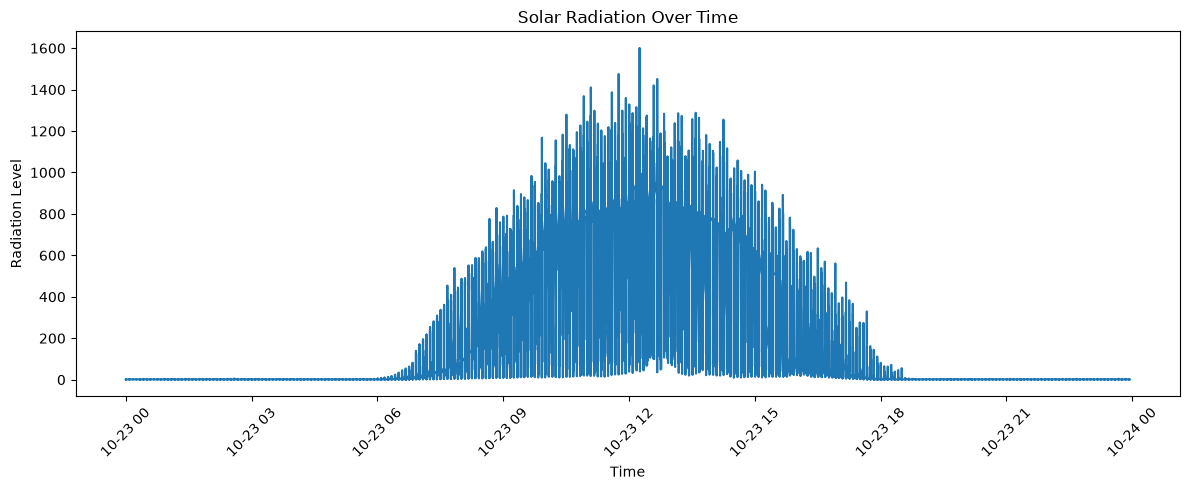

In [5]:
import matplotlib.pyplot as plt


# 1. Convert Time to datetime and sort so lines don't criss-cross
df['Time'] = pd.to_datetime(df['Time'])
df = df.sort_values('Time')

# 2. Set a wider figure size for better visibility
plt.figure(figsize=(12, 5))

# 3. Plot the data
plt.plot(df['Time'], df['Radiation'])
plt.title('Solar Radiation Over Time')
plt.xlabel('Time')
plt.ylabel('Radiation Level')

# 4. Rotate x-axis labels 45 degrees so they don't overlap
plt.xticks(rotation=45)

# 5. Automatically adjust layout so labels aren't cut off
plt.tight_layout()
plt.show()

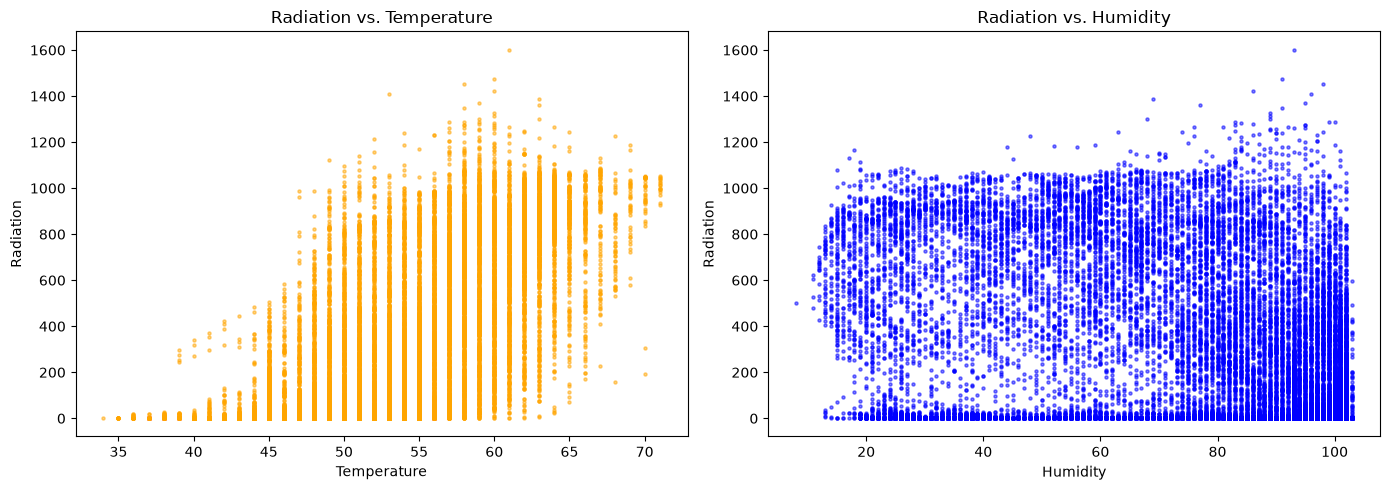

In [8]:
# Create a figure with two side-by-side charts
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Chart 1: Radiation vs Temperature
ax1.scatter(df['Temperature'], df['Radiation'], alpha=0.5, color='orange',s=5)
ax1.set_title('Radiation vs. Temperature')
ax1.set_xlabel('Temperature')
ax1.set_ylabel('Radiation')

# Chart 2: Radiation vs Humidity
ax2.scatter(df['Humidity'], df['Radiation'], alpha=0.5, color='blue',s=5)
ax2.set_title('Radiation vs. Humidity')
ax2.set_xlabel('Humidity')
ax2.set_ylabel('Radiation')

plt.tight_layout()
plt.show()

In [9]:
# Count the number of unique days in the dataset
total_days = df['Data'].nunique()
print(f"There are {total_days} days of data.")

There are 118 days of data.


In [10]:
# Group by the date column (assuming it is named 'Data') to calculate max and average
daily_summary = df.groupby('Data')['Radiation'].agg(['max', 'mean']).reset_index()
daily_summary.rename(columns={'max': 'Max_Radiation', 'mean': 'Avg_Radiation'}, inplace=True)

# Sort the table to find the top 5 days with the highest average radiation
top_5_avg_days = daily_summary.sort_values(by='Avg_Radiation', ascending=False).head(5)
print("Top 5 Days by Average Radiation:")
print(top_5_avg_days)

Top 5 Days by Average Radiation:
                      Data  Max_Radiation  Avg_Radiation
99   9/19/2016 12:00:00 AM        1085.75     335.504400
100   9/2/2016 12:00:00 AM        1062.01     333.471219
103  9/22/2016 12:00:00 AM        1053.17     325.515880
106  9/25/2016 12:00:00 AM        1075.29     319.921514
109  9/28/2016 12:00:00 AM        1029.30     312.400390


/var/folders/l4/48vnbbln301c8h2x6d1sm93m0000gn/T/ipykernel_3741/2883163860.py:3: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  daily_summary.rename(columns={'max': 'Max_Radiation', 'mean': 'Avg_Radiation'}, inplace=True)


In [14]:
# Sort the summary table by the maximum radiation column
top_5_max_days = daily_summary.sort_values(by='Max_Radiation', ascending=False).head(5)

print("Top 5 Days by Maximum Radiation:")
print(top_5_max_days)

Top 5 Days by Maximum Radiation:
                       Data  Max_Radiation  Avg_Radiation
112    9/4/2016 12:00:00 AM        1601.26     153.584321
10   10/19/2016 12:00:00 AM        1451.41     183.265208
28    10/7/2016 12:00:00 AM        1420.39     180.155599
24   10/31/2016 12:00:00 AM        1410.52     194.996829
108   9/27/2016 12:00:00 AM        1387.17     220.851210


In [13]:
# Find the exact row containing the absolute highest radiation value
max_rad_row = df.loc[df['Radiation'].idxmax()]

print("--- SOLAR FLARE EVENT DETECTED ---")
print(f"Date: {max_rad_row['Data']}")
print(f"Time of Peak: {max_rad_row['Time']}")
print(f"Peak Radiation: {max_rad_row['Radiation']}")
print(f"Temperature: {max_rad_row['Temperature']}")
print(f"Humidity: {max_rad_row['Humidity']}")

# Note: Check your dataset to see if Wind is named 'WindDirection(Degrees)' or 'Speed'
print(f"Wind Data: {max_rad_row.get('WindDirection(Degrees)', 'Column Name Varies')}")

import datetime

# Extract the string times (Double check if 'TimeSunRise' is spelled differently in your CSV)
peak_time_str = max_rad_row['Time']
sunrise_time_str = max_rad_row['TimeSunRise']

# Convert to datetime objects to subtract them
peak_dt = pd.to_datetime(peak_time_str).time()
sunrise_dt = pd.to_datetime(sunrise_time_str).time()

# Combine with a dummy date to perform the math
dummy_date = datetime.date(2000, 1, 1)
time_diff = datetime.datetime.combine(dummy_date, peak_dt) - datetime.datetime.combine(dummy_date, sunrise_dt)
print(f"Sunrise Time on Peak Day: {max_rad_row['TimeSunRise']}")
print(f"The maximum radiation occurred {time_diff} after sunrise.")

--- SOLAR FLARE EVENT DETECTED ---
Date: 9/4/2016 12:00:00 AM
Time of Peak: 2026-10-23 12:15:04
Peak Radiation: 1601.26
Temperature: 61
Humidity: 93
Wind Data: 3.56
Sunrise Time on Peak Day: 06:08:00
The maximum radiation occurred 6:07:04 after sunrise.


In [16]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np
import pandas as pd

# 1. Prepare the Features (The Inputs)
# Extract the hour directly from the original 'Time' column
df['Hour'] = pd.to_datetime(df['Time']).dt.hour

# Select our environmental triggers using your EXACT column names
X = df[['Temperature', 'Humidity', 'Hour', 'Speed', 'Pressure']] 
y = df['Radiation'] 

# 2. Split the Data (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Train the Machine
model = RandomForestRegressor(random_state=42)
model.fit(X_train, y_train)

# 4. Make Predictions and Grade the Test
predictions = model.predict(X_test)

rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print(f"RMSE (Average Error Margin): {rmse:.2f}")
print(f"R-squared Score: {r2:.2f}")

# 5. Which feature mattered most?
importances = model.feature_importances_
print("\n--- Feature Importance ---")
for feature, importance in zip(X.columns, importances):
    print(f"{feature}: {importance * 100:.1f}%")

RMSE (Average Error Margin): 95.82
R-squared Score: 0.91

--- Feature Importance ---
Temperature: 58.1%
Humidity: 6.6%
Hour: 29.2%
Speed: 2.4%
Pressure: 3.7%


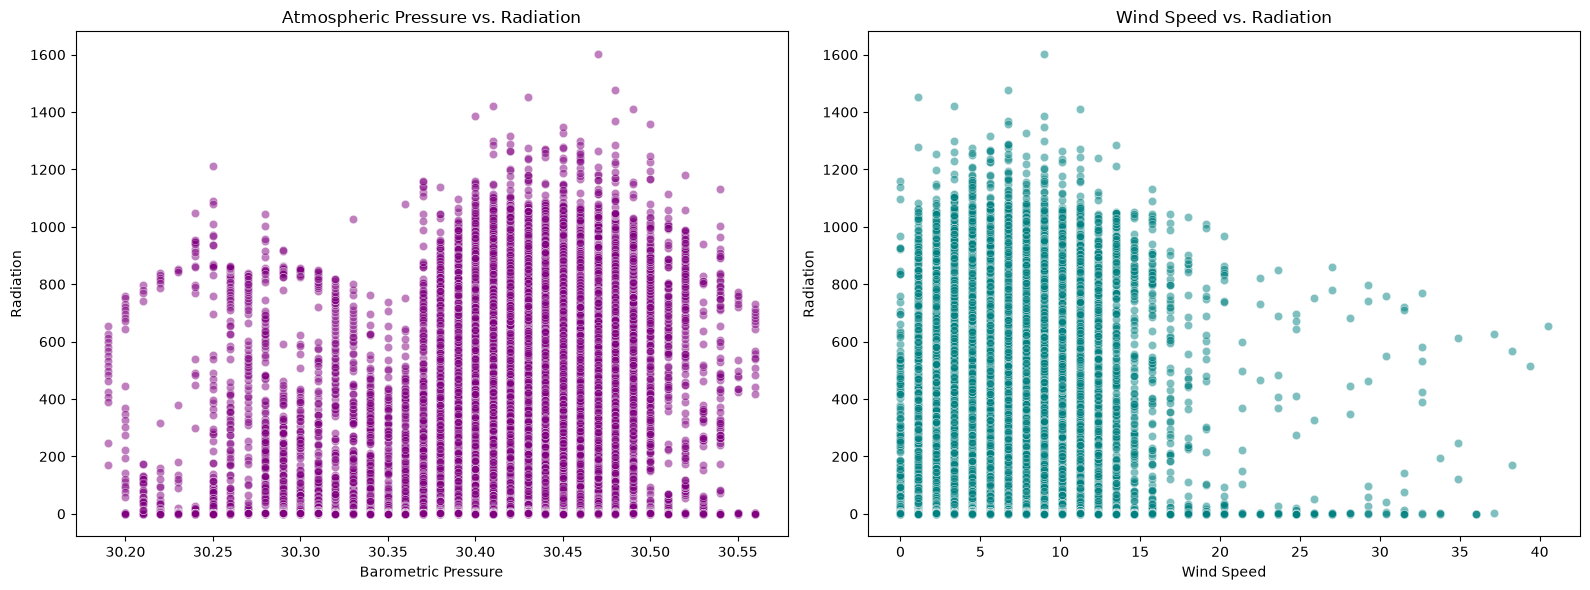

In [32]:


import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Ensure the Time column is treated as a datetime object
df['Datetime'] = pd.to_datetime(df['Time'])

# Extract the month name (e.g., 'September', 'October')
df['Month_Name'] = df['Datetime'].dt.month_name()


# ---------------------------------------------------------
# GRAPH 2: Exploring the Hidden Factors (Pressure & Speed)
# ---------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Subplot A: Pressure vs Radiation
sns.scatterplot(data=df, x='Pressure', y='Radiation', alpha=0.5, ax=ax1, color='purple')
ax1.set_title('Atmospheric Pressure vs. Radiation')
ax1.set_xlabel('Barometric Pressure')

# Subplot B: Wind Speed vs Radiation
sns.scatterplot(data=df, x='Speed', y='Radiation', alpha=0.5, ax=ax2, color='teal')
ax2.set_title('Wind Speed vs. Radiation')
ax2.set_xlabel('Wind Speed')

plt.tight_layout()
plt.show()

/var/folders/l4/48vnbbln301c8h2x6d1sm93m0000gn/T/ipykernel_3741/943255073.py:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Date_Only'] = pd.to_datetime(df['Data']).dt.strftime('%Y-%m-%d')


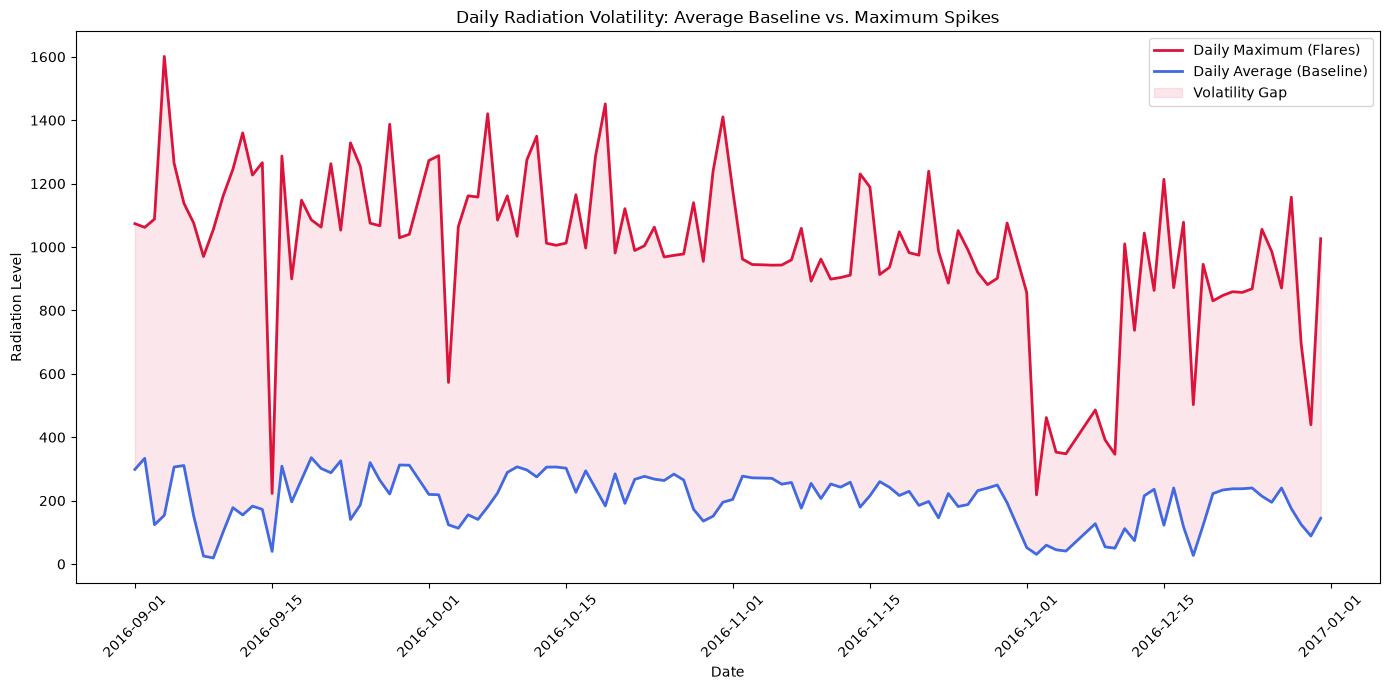

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Prepare the daily data
df['Date_Only'] = pd.to_datetime(df['Data']).dt.strftime('%Y-%m-%d')
daily_stats = df.groupby('Date_Only')['Radiation'].agg(['max', 'mean']).reset_index()

# Convert back to datetime for smooth timeline plotting
daily_stats['Date_Only'] = pd.to_datetime(daily_stats['Date_Only'])

# 2. Create the distribution line graph
plt.figure(figsize=(14, 7))

# Plot the Maximums
sns.lineplot(data=daily_stats, x='Date_Only', y='max', 
             label='Daily Maximum (Flares)', color='crimson', linewidth=2)

# Plot the Averages
sns.lineplot(data=daily_stats, x='Date_Only', y='mean', 
             label='Daily Average (Baseline)', color='royalblue', linewidth=2)

# 3. Fill the gap between the lines to visually highlight the extreme difference
plt.fill_between(daily_stats['Date_Only'], daily_stats['mean'], daily_stats['max'], 
                 color='crimson', alpha=0.1, label='Volatility Gap')

plt.title('Daily Radiation Volatility: Average Baseline vs. Maximum Spikes')
plt.xlabel('Date')
plt.ylabel('Radiation Level')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [30]:
import pandas as pd

# 1. Convert Data and Time into a proper Datetime column
df['Date_Only'] = pd.to_datetime(df['Data']).dt.strftime('%Y-%m-%d')
df['Datetime'] = pd.to_datetime(df['Date_Only'] + ' ' + df['Time'].astype(str))

# 2. Group by date and calculate daily maximum and average radiation
daily_stats = df.groupby('Date_Only')['Radiation'].agg(['max', 'mean']).reset_index()
daily_stats = daily_stats.rename(columns={'max': 'Max_Radiation', 'mean': 'Avg_Radiation'})

# 3. Determine the date with the highest recorded solar radiation
max_rad_row = df.loc[df['Radiation'].idxmax()]

highest_date = max_rad_row['Date_Only']
highest_rad = max_rad_row['Radiation']

# 4. Extract time, temperature, humidity, and wind speed for that peak event
peak_time = str(max_rad_row['Time'])
peak_temp = max_rad_row['Temperature']
peak_hum = max_rad_row['Humidity']
peak_wind = max_rad_row['Speed']

# 5. Compare with sunrise and calculate duration after sunrise
sunrise_time = str(max_rad_row['TimeSunRise'])

# FIX: Strip any hidden timezones from both times before doing the math
sunrise_dt = pd.to_datetime(highest_date + ' ' + sunrise_time).replace(tzinfo=None)
peak_dt = pd.to_datetime(highest_date + ' ' + peak_time).replace(tzinfo=None)

# Calculate the exact time difference
duration_after_sunrise = peak_dt - sunrise_dt
hours, remainder = divmod(duration_after_sunrise.total_seconds(), 3600)
minutes = remainder // 60

# 6. Identify the top 5 days with the highest average radiation
top_5_days = daily_stats.sort_values(by='Avg_Radiation', ascending=False).head(5)

# --- PRINT THE REPORT-READY OUTPUT ---
print("=== SOLAR OBSERVATION DATA ANALYSIS ===\n")

print("1. MAXIMUM RADIATION EVENT")
print(f"Date of Highest Radiation: {highest_date}")
print(f"Maximum Radiation Recorded: {highest_rad:.2f} units\n")

print("2. ENVIRONMENTAL CONDITIONS DURING PEAK")
print(f"Time of Peak: {peak_time}")
print(f"Temperature: {peak_temp}°")
print(f"Humidity: {peak_hum}%")
print(f"Wind Speed: {peak_wind}\n")

print("3. SUNRISE COMPARISON")
print(f"Sunrise Time: {sunrise_time}")
print(f"Time Elapsed Since Sunrise: {int(hours)} hours and {int(minutes)} minutes\n")

print("4. TOP 5 DAYS (HIGHEST AVERAGE RADIATION)")
print(top_5_days.to_string(index=False, formatters={'Max_Radiation': '{:.2f}'.format, 'Avg_Radiation': '{:.2f}'.format}))

/var/folders/l4/48vnbbln301c8h2x6d1sm93m0000gn/T/ipykernel_3741/1284786979.py:4: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Date_Only'] = pd.to_datetime(df['Data']).dt.strftime('%Y-%m-%d')
/var/folders/l4/48vnbbln301c8h2x6d1sm93m0000gn/T/ipykernel_3741/1284786979.py:5: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Datetime'] = pd.to_datetime(df['Date_Only'] + ' ' + df['Time'].astype(str))


=== SOLAR OBSERVATION DATA ANALYSIS ===

1. MAXIMUM RADIATION EVENT
Date of Highest Radiation: 2016-09-04
Maximum Radiation Recorded: 1601.26 units

2. ENVIRONMENTAL CONDITIONS DURING PEAK
Time of Peak: 2026-10-23 12:15:04
Temperature: 61°
Humidity: 93%
Wind Speed: 9.0

3. SUNRISE COMPARISON
Sunrise Time: 06:08:00
Time Elapsed Since Sunrise: 6 hours and 7 minutes

4. TOP 5 DAYS (HIGHEST AVERAGE RADIATION)
 Date_Only Max_Radiation Avg_Radiation
2016-09-19       1085.75        335.50
2016-09-02       1062.01        333.47
2016-09-22       1053.17        325.52
2016-09-25       1075.29        319.92
2016-09-28       1029.30        312.40
